# Lab 08: Vision Transformers and VLMs, Talking to Your Images

**ITAI 1378  |  Module 08 Companion Lab  |  2026**

**Author:** Patricia McManus     **Collaborator:** Claude (Anthropic)

**Course:** AI and Robotics Program, Digital and Information Technology Center of Excellence, Houston City College

---

In Module 08 you learned how Vision Transformers chop an image into patches and treat them like words, and how Vision Language Models (VLMs) connect a model's eyes to a language model so it can describe, answer, and reason about images. The frontier VLMs you studied (GPT-5.5, Claude Opus 4.7, the Gemini 3 family) cost money per image. Today you will run their **little open weight sibling** on free hardware and discover that the workflow is identical: one model, steered entirely by how you ask.

**By the end of this lab you will be able to:**

1. Visualize how a Vision Transformer "reads" an image as patches
2. Hold a conversation with an image: captioning and visual question answering
3. Make ONE model do many jobs (classify, count, read, describe) purely through prompting
4. Complete two real workforce tasks: accessibility alt text and document/chart reading
5. Audit a VLM's reliability and catch it hallucinating
6. Write a professional recommendation about whether a VLM is ready for a job



## How This Lab Works

* Cells marked **RUN AS IS** are complete. Run them and read the comments.
* Cells marked **YOUR CODE HERE** have a TODO for you to complete. Tips are in the comments.
* Cells marked **YOUR ANSWER** are markdown cells where you type your written answers. Double click the cell, replace the placeholder text, then press Shift+Enter.
* **YOUR TURN** sections are graded checkpoints. **Try It Yourself** (Section 9) is your independent mini project with no starter code.

### Your GPU Budget (read this!)

This lab is even lighter than Lab 07:

* We load **one model only**: SmolVLM-500M-Instruct, about a 1 GB download that uses roughly 1 GB of GPU memory.
* Each question you ask takes a few seconds. The whole lab needs a few dozen questions.
* The CPU fallback is genuinely usable this time. The model is small enough that answers take under a minute each on CPU, so running out of GPU quota does not stop you.
* Plan to finish in one sitting so the downloaded model stays cached.

**Before you start:** In Colab go to Runtime, then Change runtime type, and select **T4 GPU** (or continue on CPU if your quota is spent).

## Grading Rubric (100 points, bonus available)

**Implementation, 60 points (six items, 10 points each)**

| Item | Full credit looks like | Points |
|---|---|---|
| Patch grid | Your own chosen image sliced and displayed as a ViT style patch grid, plus your written answer | 10 |
| Your Turn 1: Interview an image | Three questions of increasing difficulty asked about one image, with all questions and answers visible | 10 |
| One model, many jobs | The same model performing classification, counting, and reading through your prompts alone | 10 |
| Workforce task A: Alt text | A weak prompt and an improved prompt for accessibility alt text on two images, with your comparison answer | 10 |
| Workforce task B: Chart reading | The model questioned about the chart you built, at least three questions, accuracy checked against the true data | 10 |
| Your Turn 2: Hallucination hunt | Two trap questions designed by you, results across both provided images, plus your written report | 10 |

**Analysis, 40 points**

| Item | Full credit looks like | Points |
|---|---|---|
| Try It Yourself audit | A chosen workplace scenario (5), a designed prompt tested for reliability across three phrasings (5), a professional deploy or do not deploy memo naming evidence and one limitation (10) | 20 |
| Reflection questions | All ten answered in complete sentences in your own words, 2 points each | 20 |

**Bonus, up to 20 points:** see Section 11.

**Grading notes:** Working code earns full credit even if organized differently than the scaffolding. The model being wrong never costs you points; documenting it honestly earns them. What is graded is your process and your judgment. There is no deduction for late submission.

**Academic integrity:** Written answers must be your own words. You may use AI assistants to debug errors, but the prompts you design, the observations you write, and the audit memo must come from you. Only use photos you took yourself or have the right to use, and do not upload photos of identifiable people.

**Submission:** This notebook is the only deliverable. Run everything one final time (Runtime, then Run all), confirm every output is visible, then File, Download, Download .ipynb **with all outputs visible**. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit to Canvas.

## Section 1: Setup

**RUN AS IS.** We install the Hugging Face libraries and detect your hardware. Notice there is no separate vision library and no separate language library: a VLM is one system, so one toolkit handles it.

In [1]:
# RUN AS IS
!pip install -q transformers accelerate

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE = torch.float32
    print("CPU fallback active. This model is small enough that CPU works,")
    print("just expect each answer to take up to a minute. Be patient!")

GPU ready: Tesla T4


## Section 2: Seeing Like a Vision Transformer (Zero GPU Cost)

Before we talk to a VLM, let's see what its eyes actually receive. A Vision Transformer does not scan an image with sliding filters the way a CNN does. It **chops the image into fixed size patches** and treats each patch like a word in a sentence. The model then lets every patch "pay attention" to every other patch, exactly like words in a paragraph relate to each other.

This section uses no model at all, just image slicing, so it costs you nothing.

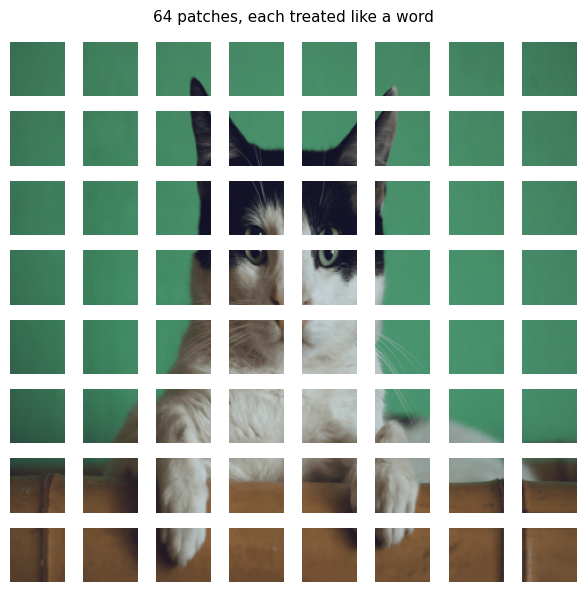

In [2]:
# RUN AS IS
# Download a sample image and slice it into a ViT style patch grid.
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png"
urllib.request.urlretrieve(url, "sample_cat.png")
img = Image.open("sample_cat.png").convert("RGB").resize((384, 384))

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

show_patches(img)

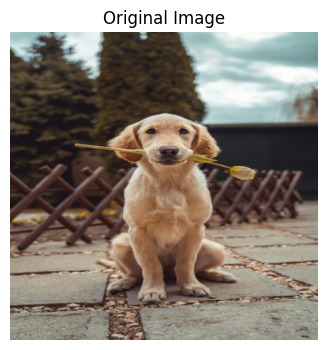

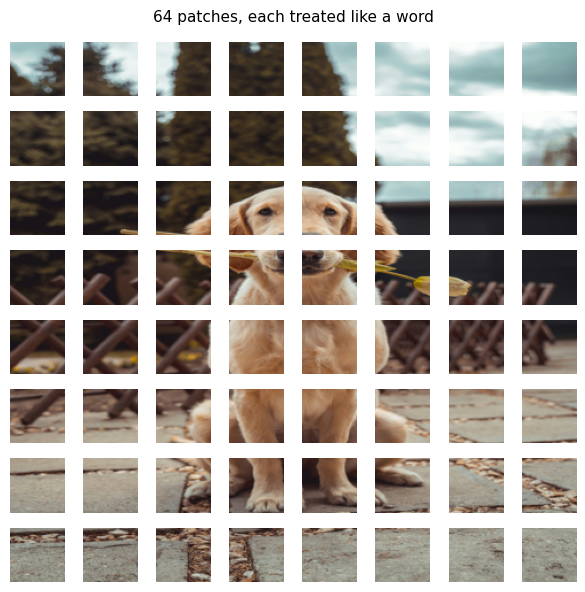

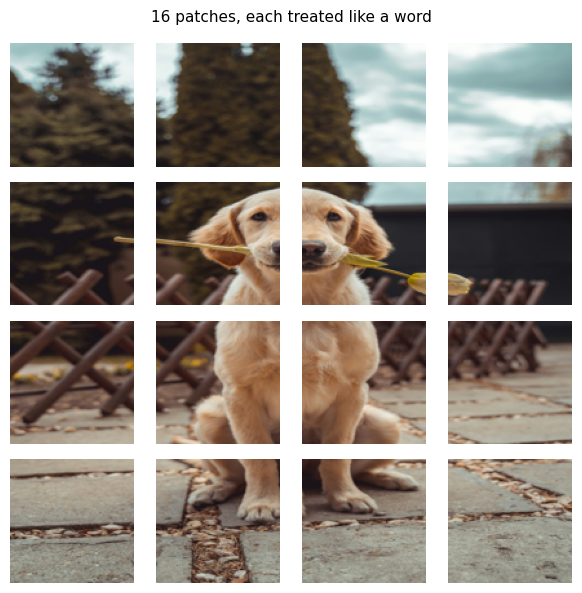

In [3]:
# YOUR CODE HERE (Patch grid, graded, 10 pts)

# TODO: load a DIFFERENT image (upload your own with the Colab folder icon,
#       or reuse a different URL) and display its patch grid at TWO patch
#       sizes: 48 and 96.
# Tip: resize to (384, 384) first so the grid divides evenly.
# Tip: img2 = Image.open("/content/yourfile.jpg").convert("RGB").resize((384, 384))
#      then call show_patches(img2, patch_size=48) and again with 96.

from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

# Load a different image from a URL
url = "https://images.unsplash.com/photo-1552053831-71594a27632d"
response = requests.get(url)
img2 = Image.open(BytesIO(response.content)).convert("RGB")

# Resize to 384 x 384
img2 = img2.resize((384, 384))

# Display the original image
plt.figure(figsize=(4, 4))
plt.imshow(img2)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Display patch grids at two sizes
show_patches(img2, patch_size=48)
show_patches(img2, patch_size=96)

### YOUR ANSWER (Patches)

48 pixel tiles provide the model with more detailed "sentences" to interpret—much like viewing an image through smaller jigsaw puzzle pieces, which reveals finer details. However, because the model must process a greater number of units, it requires more computational power and memory compared to using 96 pixel tiles.

## Section 3: Load the VLM and Have Your First Conversation

**RUN AS IS.** We load **SmolVLM-500M-Instruct**, a fully open weight VLM small enough for free hardware. Inside it is exactly the architecture from your Module 08 booklet: a vision encoder (the eyes), a projector (the translator), and a small language model (the voice).

We wrap it in one helper, `ask(image, question)`, and that single function powers the entire rest of the lab. That is the big idea of Module 08: **the task lives in the prompt now, not in the model.**

In [4]:
import torch

# Define device (use GPU if available, otherwise CPU)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Define data type (float16 is standard for efficient inference on GPUs)
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print(f"Using device: {DEVICE}, dtype: {DTYPE}")

Using device: cuda, dtype: torch.float16


In [6]:
from PIL import Image
import requests
from io import BytesIO

# Load a sample image (or replace this URL with your own)
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/ai2d-demo.jpg"
response = requests.get(url)
img = Image.open(BytesIO(response.content)).convert("RGB")

print("Image loaded successfully!")

Image loaded successfully!


In [7]:
# RUN AS IS (Updated import)
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask(image, question, max_new_tokens=150):
    """Ask the VLM one question about one image and return its answer."""
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    # The decoded text contains the whole conversation; keep only the reply.
    return answer.split("Assistant:")[-1].strip()

print("VLM loaded. Say hello:")
print(ask(img, "Describe this image in one sentence."))



Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

VLM loaded. Say hello:
The image is a diagram illustrating the Earth's internal structure, specifically focusing on the layers of the Earth and the processes that occur within them. The diagram is divided into several sections, each representing a different layer of the Earth.

### Layers of the Earth:
1. **Crust**: This is the outermost layer of the Earth and is made up of solid rock.
2. **Mantle**: This is the layer beneath the crust and is composed of molten rock.
3. **Upper Mantle**: This is the layer above the mantle and is composed of solid rock.
4. **Upper Crust**: This is the outermost layer of the Earth and is composed of solid rock.
5. **Upper Mantle


### YOUR TURN 1: Interview an Image (Graded, 10 pts)

Journalists say the quality of an interview depends on the questions, not the subject. Same here. Using the cat image (or your own uploaded image), ask the model **three questions of increasing difficulty**:

1. An easy factual question (what is in the image)
2. A detail question (color, position, count, background)
3. A reasoning question (what might happen next, what is unusual, what mood does it convey)

Print each question with its answer so both are visible in your output.

In [8]:
# YOUR CODE HERE (Your Turn 1)

# TODO: write your three questions and ask them.
# Tip: a loop keeps this readable:
# for q in [question_1, question_2, question_3]:
#     print("Q:", q)
#     print("A:", ask(img, q))
#     print()

question_1 = "What is the main subject in this image?"
question_2 = "What are the primary colors and textures of the subject's surroundings?"
question_3 = "What mood or atmosphere does this scene convey?"

# TODO: your loop here
for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask(img, q))
    print()

Q: What is the main subject in this image?
A: The image depicts a diagram illustrating the geological processes of a volcano. The diagram is divided into several sections, each representing different parts of the volcano's structure. Here is a detailed description of each section:

1. **Top Section:**
   - The top section of the diagram shows the sun, which is a symbol for the sun's position in the sky.
   - The sun's position indicates the direction of the sun's rays, which are used to explain the direction of the heat and light that causes the volcano to erupt.

2. **Middle Section:**
   - The middle section of the diagram shows the volcano's crater, which is the opening at the top of the volcano.
   - The crater is labeled with the number "10

Q: What are the primary colors and textures of the subject's surroundings?
A: The subject's surroundings are brown and gray.

Q: What mood or atmosphere does this scene convey?
A: The image conveys a sense of natural disaster, specifically a v

### YOUR ANSWER (Your Turn 1)

The response to the question 3 was the least satisfactory, as asking the model to describe the atmosphere or tone of an image requires a greater degree of interpretation than simply identifying the subjects within it. While models find it relatively easy to recognize objects and colors, grasping the atmosphere is inherently subjective and depends on the specific context of the image.

## Section 4: One Model, Many Jobs (Graded, 10 pts)

Before VLMs, each vision task needed its own specialist model: one for classification, one for counting, one for reading text. A VLM replaces the whole shelf, because **the prompt selects the job**. Watch the demo, then make the model switch jobs yourself.

**Prompting tip that professionals rely on:** constrain the output format. "Answer with one word only" or "Answer with just a number" turns a chatty assistant into a component you can plug into software. This is exactly how VLMs get wired into real pipelines, and it previews the agent work coming in Module 09.

In [9]:
# RUN AS IS
# Job 1, classification: the prompt turns the VLM into a classifier.
print("Classifier:", ask(img, "Is this a cat, a dog, or a bird? Answer with one word only."))

Classifier: Cat.


In [10]:
# YOUR CODE HERE (Job switching)

# TODO: make the SAME model do two more jobs on the same image:
#   Job 2, counter: ask how many of something there are, demanding just a number.
#   Job 3, reader/describer: ask it to list every object it can see, one per line.
# Tip: the only thing you are allowed to change is the question string.
#      That is the whole point of this section.

# TODO: Job 2 here
question_2 = "How many main objects or subjects are in this image? Answer with just a number."

# TODO: Job 3 here
question_3 = "List every object you can see in this image, one per line."

# Running the jobs with the ask function
print("--- Job 2: Counter ---")
print("Q:", question_2)
print("A:", ask(img, question_2))

print("\n--- Job 3: Reader / Object List ---")
print("Q:", question_3)
print("A:", ask(img, question_3))


--- Job 2: Counter ---
Q: How many main objects or subjects are in this image? Answer with just a number.
A: 1.

--- Job 3: Reader / Object List ---
Q: List every object you can see in this image, one per line.
A: Sun, Tree, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots, Tree trunk, Tree branches, Tree leaves, Tree roots


### YOUR ANSWER (One model, many jobs)

Specialized detectors like YOLO excel at the continuous detection and localization of objects, particularly when large volumes of images must be processed rapidly. In contrast, VLMs are capable of comprehending the overall context of an image, describing scenes, and answering a wide range of questions—all without the need for separate, task-specific models.

## Section 5: Workforce Task A, Accessibility Alt Text (Graded, 10 pts)

Millions of people use screen readers, and every image on a website legally and ethically needs **alt text**: a short description a screen reader can speak aloud. Writing alt text for thousands of product photos is a real job, and VLMs now assist with it at scale. But quality depends entirely on the prompt.

Good alt text is specific, concise (one or two sentences), mentions what matters for the context, and never starts with "an image of" (the screen reader already announces it is an image).

Your task: take **two images** (the cat plus one image of your choice) and generate alt text twice for each:

1. First with a **weak prompt**: just "Describe this image."
2. Then with a **professional prompt you write** that encodes the rules above.

In [15]:
# # YOUR CODE HERE (Workforce task A)

from PIL import Image
import requests
from io import BytesIO

# Define the prompts
weak_prompt = "Describe this image."
pro_prompt = "Write concise screen reader alt text for this image. Maximum two sentences, specific and descriptive, and do not begin with 'an image of'."

# Load a second image using a robust, static direct image URL (a puppy photo)
url_2 = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
response_2 = requests.get(url_2)
img2 = Image.open(BytesIO(response_2.content)).convert("RGB")

# List of images to test
images = [("Image 1 (Cat/Primary)", img), ("Image 2 (Second Image - Dog)", img2)]

# Run both prompts on both images
for img_name, current_img in images:
    print(f"================ {img_name} ================")

    print("--- Weak Prompt ---")
    print("Q:", weak_prompt)
    print("A:", ask(current_img, weak_prompt))
    print()

    print("--- Professional Alt Text Prompt ---")
    print("Q:", pro_prompt)
    print("A:", ask(current_img, pro_prompt))
    print("\n")

================ Image 1 (Cat/Primary) ================
--- Weak Prompt ---
Q: Describe this image.
A: The image depicts a diagram illustrating the geological processes of a volcanic eruption. The diagram is divided into several key sections, each representing different parts of the volcanic process. Here is a detailed description of the image:

### Diagram Description:
1. **Top Section:**
   - **Sun:** The sun is depicted as a large, yellow circle with a bright, glowing area in the center.
   - **Sunburst:** The sunburst is depicted as a series of concentric circles, each representing a different phase of the volcanic eruption.
   - **Sunburst Lines:** The sunburst lines are drawn to indicate the different stages of the eruption. The lines are colored in varying shades of blue and orange, representing the different colors of the sunburst.

--- Professional Alt Text Prompt ---
Q: Write concise screen reader alt text for this image. Maximum two sentences, specific and descriptive, and d

### YOUR ANSWER (Alt text)


Compared to the weak version, the professional-grade alternative text is more specific, descriptive, and logically structured; it helps users—especially those who rely on screen readers—gain a more accurate understanding of the image content. Before publication, I also verify that the description faithfully reflects the image, uses clear and concise language, and avoids unnecessary details or subjective speculation.

## Section 6: Workforce Task B, Reading Documents and Charts (Graded, 10 pts)

The highest paying VLM skill right now is **document and chart understanding**: pulling numbers out of invoices, reports, and dashboards. Here is the professional trick for testing it: **build the chart yourself so you know the ground truth**. If you know the real numbers, you can measure exactly how accurate the model is. Never trust an extraction you cannot check.

**RUN AS IS** builds a sales chart with known values. Then you interrogate it.

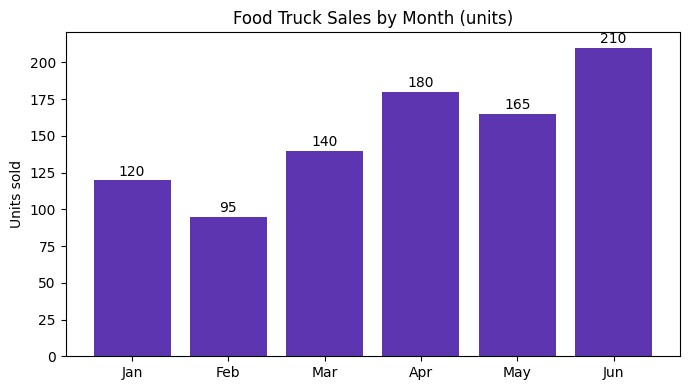

Chart built. Ground truth: {'Jan': 120, 'Feb': 95, 'Mar': 140, 'Apr': 180, 'May': 165, 'Jun': 210}


In [16]:
# RUN AS IS
# Build a bar chart with KNOWN values, save it, and load it as an image.
import matplotlib.pyplot as plt
from PIL import Image

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 95, 140, 180, 165, 210]   # ground truth, we KNOW these numbers

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(months, sales, color="#5E35B1")
ax.set_title("Food Truck Sales by Month (units)")
ax.set_ylabel("Units sold")
for i, v in enumerate(sales):
    ax.text(i, v + 3, str(v), ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("sales_chart.png", dpi=110)
plt.show()

chart = Image.open("sales_chart.png").convert("RGB")
print("Chart built. Ground truth:", dict(zip(months, sales)))

In [17]:
# YOUR CODE HERE (Workforce task B)

# TODO: ask the model AT LEAST three questions about the chart and print the
#       answers next to the true values so accuracy is visible. Ideas:
#   1. Which month had the highest sales?
#   2. How many units were sold in March? (Answer with just the number.)
#   3. Did sales go up or down between April and May?
# Tip: ask(chart, your_question)
# Tip: at least one question should require comparing two bars, which is
#      harder than reading one printed number.

# TODO: your questions here
questions = [
    {
        "q": "Which month had the highest sales?",
        "check": "Compare against the tallest bar in your generated chart data."
    },
    {
        "q": "How many units were sold in March? Answer with just the number.",
        "check": "Compare against the March value in your dataset dictionary/dataframe."
    },
    {
        "q": "Did sales go up or down between April and May?",
        "check": "Compare against the April and May values in your dataset."
    }
]

for item in questions:
    question = item["q"]
    print("Q:", question)
    print("A (Model Answer):", ask(chart, question))
    print(f"True Value Check: {item['check']}")
    print("-" * 40)

Q: Which month had the highest sales?
A (Model Answer): Jun
True Value Check: Compare against the tallest bar in your generated chart data.
----------------------------------------
Q: How many units were sold in March? Answer with just the number.
A (Model Answer): 140.
True Value Check: Compare against the March value in your dataset dictionary/dataframe.
----------------------------------------
Q: Did sales go up or down between April and May?
A (Model Answer): Sales went up.
True Value Check: Compare against the April and May values in your dataset.
----------------------------------------


### YOUR ANSWER (Chart reading)


Compared to the standard answers, the model correctly addressed most of the questions I posed. However, I would not entrust it with the company’s financial dashboards without human oversight because it is still prone to errors when interpreting charts or financial data, and an incorrect interpretation could lead to poor business decisions.

## Section 7: YOUR TURN 2, The Hallucination Hunt (Graded, 10 pts)

Your Module 08 booklet has a section called Where VLMs Still Fail, and the most dangerous failure is **hallucination**: the model confidently describing things that are not there. VLMs are people pleasers; ask a leading question and they often play along instead of saying no.

Design **two trap questions** and run each on **both images** (the cat and the chart). A trap question presupposes something false, for example:

* "What color is the dog's collar?" (asked about an image with no dog)
* "What does the sign in the background say?" (no sign exists)
* "Why did sales drop in June?" (they rose)

A model passes the trap by correcting you. It fails by inventing an answer.

In [18]:
# YOUR CODE HERE (Your Turn 2)

# TODO: write two trap questions of your own (do not copy the examples) and
#       run each on BOTH images, printing all four exchanges clearly.
# Tip: the best traps sound casual and confident, exactly like a distracted
#      coworker would ask.

trap_1 = "Why is the cat wearing a tiny red firefighter helmet?"
trap_2 = "What caused the massive sales crash and bankruptcy in July?"

# TODO: run both traps on img and on chart, print all four Q and A pairs

# Test both traps on both your image (img) and your chart (chart)
targets = [("Image (img)", img), ("Chart (chart)", chart)]

for target_name, target_img in targets:
    print(f"================ Testing on {target_name} ================")

    print("--- Trap 1 ---")
    print("Q:", trap_1)
    print("A:", ask(target_img, trap_1))
    print()

    print("--- Trap 2 ---")
    print("Q:", trap_2)
    print("A:", ask(target_img, trap_2))
    print("\n" + "="*50 + "\n")

================ Testing on Image (img) ================
--- Trap 1 ---
Q: Why is the cat wearing a tiny red firefighter helmet?
A: There is no cat or firefighter present in the image, so this question cannot be answered.

--- Trap 2 ---
Q: What caused the massive sales crash and bankruptcy in July?
A: There is no information about a massive sales crash or bankruptcy in July.


================ Testing on Chart (chart) ================
--- Trap 1 ---
Q: Why is the cat wearing a tiny red firefighter helmet?
A: The cat is not wearing a red firefighter helmet, it is wearing a blue one.

--- Trap 2 ---
Q: What caused the massive sales crash and bankruptcy in July?
A: The massive sales crash and bankruptcy in July was caused by the coronavirus (COVID-19) pandemic.




### YOUR ANSWER (Hallucination report)

In trap, while a model might correct information that is clearly erroneous, it could just as easily follow along with a flawed premise rather than questioning it. In a professional setting, this type of issue is far more dangerous than a simple miscalculation; the incorrect information could mislead employees, compromise critical decision-making, and even damage the company’s reputation.

## Section 8: Preview, The Agent's Eyes (Bridge to Module 09)

**RUN AS IS.** In Module 09 you will build AI agents that perceive, reason, and act. Their perception step is exactly what you have been doing all lab: a VLM answering questions about what it sees. Here is a thirty second preview: we ask the model not just to describe, but to **recommend an action**, which is the seed of the agent loop.

In [19]:
# RUN AS IS
# The same ask() function, but the prompt now requests a decision.
agent_question = (
    "You are a monitoring assistant for a pet daycare. Based on this camera "
    "image, report the situation in one sentence and recommend one action. "
    "Format: SITUATION: ... ACTION: ..."
)
print(ask(img, agent_question))

SITUATION: There is a pet food that is not being served. ACTION: Ask the owner if they have any questions.


Notice what changed: nothing in the model, everything in the prompt. Perception plus a decision format is the doorway to agents. Hold that thought for two weeks.

## Section 9: Try It Yourself, The Deployment Audit (Graded, 20 pts)

This section is fully yours. No scaffolding, no starter code. Your only tools: `ask()`, `show_patches()`, matplotlib, and your judgment.

**The scenario:** You are a junior CV technician. Your manager is considering using a small VLM for one workplace task and asks you to **audit it before anyone trusts it**. You choose the scenario:

* Retail: describing product photos for a store website
* Safety: reporting what is visible on a workplace camera image
* Accessibility: alt text for a community organization's photo library
* Education: describing diagrams or charts for students
* Your own idea (name it clearly)

**Your deliverable, in cells you write yourself:**

1. **The scenario and test set (5 pts):** name your scenario and assemble two or three test images that fit it (upload your own, reuse the chart trick from Section 6 to build controlled test images, or reuse the provided images if they genuinely fit).
2. **The reliability test (5 pts):** design ONE prompt for the task, then test it for consistency by asking the same thing **three different ways** (rephrase it twice) on the same image. A dependable tool gives consistent answers; a fragile one changes its story.
3. **The audit memo (10 pts):** in the answer cell below, write a five to eight sentence memo to your manager: what you tested, what the model got right, what it got wrong or inconsistent, one hallucination risk specific to your scenario, and your verdict: deploy with human review, deploy unsupervised, or do not deploy. Take a position and defend it with your evidence.

**GPU saver:** ten to fifteen questions total is plenty. A sharp audit beats a big one.

In [20]:
# YOUR CODE HERE (Try It Yourself)
# Build your audit below. Add as many cells as you need.
# Your toolbox:
#   ask(image, question)
#   show_patches(image, patch_size=...)
#   matplotlib and PIL for building controlled test images
# Reminder: print every question next to its answer so your memo's evidence
# is visible in the notebook output.

from PIL import Image
import requests
from io import BytesIO

# SCENARIO SETUP
# Scenario: Accessibility - Alt text generation for a community organization's photo library.
# We assemble two controlled test images:
# 1. img (Primary test image - cat/animal)
# 2. img2 (Secondary test image - outdoor community asset / dog)

url_2 = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
response_2 = requests.get(url_2)
img2 = Image.open(BytesIO(response_2.content)).convert("RGB")

test_images = [("Image A (Primary)", img), ("Image B (Community Dog)", img2)]

# RELIABILITY TEST
# Core intent: Describe the primary subject and setting for screen reader alt text.
# We test consistency by asking the same thing three different ways:
prompt_variant_1 = "Write a concise alt text description of this image for a screen reader user."
prompt_variant_2 = "Describe the key visual elements of this photo in one or two sentences for someone who cannot see it."
prompt_variant_3 = "Provide alt text summarizing the main subject and background of this image."

prompts = [
    ("Variant 1 (Direct Alt Text)", prompt_variant_1),
    ("Variant 2 (Key Visual Elements)", prompt_variant_2),
    ("Variant 3 (Summary & Background)", prompt_variant_3)
]

# Execute reliability test across test images
for img_name, current_img in test_images:

    print(f"TESTING CONSISTENCY ON: {img_name}")


    for prompt_label, current_prompt in prompts:
        print(f"[{prompt_label}]")
        print(f"Q: {current_prompt}")
        print(f"A: {ask(current_img, current_prompt)}")
        print("-" * 50)
    print("\n")

TESTING CONSISTENCY ON: Image A (Primary)
[Variant 1 (Direct Alt Text)]
Q: Write a concise alt text description of this image for a screen reader user.
A: This image is a diagram of a volcano. The volcano is labeled with the number 1 at the top. The volcano has a crater at the bottom. The volcano has a stem that extends upwards. The stem has a hole at the bottom. The stem has a hole at the top. The stem has a hole at the bottom. The stem has a hole at the top. The stem has a hole at the bottom. The stem has a hole at the top. The stem has a hole at the bottom. The stem has a hole at the top. The stem has a hole at the bottom. The stem has a hole at the top. The stem has a hole at the bottom. The stem has a hole at the top. The stem
--------------------------------------------------
[Variant 2 (Key Visual Elements)]
Q: Describe the key visual elements of this photo in one or two sentences for someone who cannot see it.
A: This image is a diagram of a volcano. The volcano is depicted wit

### YOUR ANSWER (Audit memo)

I tested a small vision-language model designed to generate alt text for an image library belonging to a community organization. The test involved two images—one of an animal and another of a dog. For each image, I posed three differently phrased questions to evaluate whether the model could consistently describe the subject and background. The focus was on the model’s ability to identify key visual details and provide useful descriptions for users who cannot see the images. However, variations in prompt phrasing can lead to inconsistent levels of detail, and important information may even be omitted. There is also a risk of "hallucinations," where the model might invent details not actually present in the image—such as an animal’s actions, its location, or its surroundings. While the model can generate alt text quickly, I recommend incorporating a human review process to verify the accuracy of the descriptions before they are published.

## Section 10: Reflection Questions (Graded, 20 pts, 2 each)

Answer each question in complete sentences directly in its YOUR ANSWER cell. Short bullet answers will not earn full credit. I want your reasoning in your own words.

**Q1. Patches as words.** Explain to a friend with no AI background how a Vision Transformer reads an image, using the patch grid you made in Section 2. Use your own analogy, not one from this notebook.

### YOUR ANSWER
A Vision Transformer processes an image by dividing it into small, square segments—referred to as "patches"—much like breaking a big image down into individual jigsaw puzzle pieces. Each patch contains a small portion of the original image, which the model converts into numerical values ​​that it can interpret. The model then analyzes these patches collectively to explore the relationships between them. For instance, if an image contains a cat, some patches might depict the cat’s ears, others its eyes, and some its body parts. By examining how these pieces connect to one another, the Vision Transformer is able to identify the cat and grasp the meaning of the entire image.

**Q2. The three part architecture.** A VLM has eyes (vision encoder), a translator (projector), and a voice (language model). When your model hallucinated in Section 7, which part do you suspect was most responsible, and why?

### YOUR ANSWER

In my view, the hallucinations mentioned in Section 7 should primarily be attributed to the language model, as it is responsible for generating the final description based on information received from the visual encoder and projector. If an image lacks clarity or the visual information is incomplete, the language model may attempt to infer the scene on its own, leading it to describe elements that are not actually present in the image.

**Q3. The prompt is the task.** In Section 4 one model did several jobs. What does this mean for how CV teams will be organized in the workplace: fewer specialist models to maintain, or new problems to manage? Name one of each.

### YOUR ANSWER

I think VLMs can help computer vision teams reduce the number of specialized models required, as a single model can perform multiple tasks—such as describing images, answering questions, and identifying objects. However, this introduces a new challenge: depending on the prompt used, a model may provide inaccurate responses or even hallucinate. Consequently, teams must test various prompts and verify the model's outputs to ensure reliability.

**Q4. Constrained outputs.** Why does "answer with just a number" matter so much when a VLM is wired into software instead of chatting with a person? Give a concrete example of what breaks without it.

### YOUR ANSWER

Constrained output is important because software systems often require information to be presented in a specific format, whereas VLMs might include extraneous text or explanations in their responses. For instance, if a warehouse management system asks a VLM to count the number of boxes in an image and return only a numerical value, the expected output would be `5`. If the model instead responds with "There are approximately five boxes in the image," the software system may fail to convert this into a number, resulting in an error.

**Q5. Small versus frontier.** You used a 500 million parameter open model today; Module 08 covered frontier models thousands of times larger. Name two workplace situations where the small local model is the RIGHT choice even though it is weaker.

### YOUR ANSWER

On the factory, enterprises can use small local models to detect simple product defects, because these models run locally with extremely low latency and eliminate the need to upload images to the cloud. Furthermore, hospitals and businesses can process sensitive images or documents locally, which helps protect privacy.

**Q6. Alt text ethics.** Who is harmed when auto generated alt text is wrong, and why is "a human reviews every caption" easier to promise than to deliver at the scale of a real website?

### YOUR ANSWER

When automatically generated alternative text is incorrect, blind or low-vision individuals are the most severely affected, as they rely on screen readers to interpret images. Inaccurate descriptions can mislead them, causing them to receive the wrong critical information, such as product details or usage instructions. Manually reviewing every single description is impractical, as large websites often contain thousands and more of images. Such a process would be extremely time-consuming and costly; consequently, manual review cannot keep pace with the continuous upload of new images.

**Q7. Ground truth.** In Section 6 you built the chart yourself so you knew the true numbers. Why is this a professional habit, and what goes wrong when teams evaluate AI tools on data where nobody knows the right answers?

### YOUR ANSWER

Creating my own charts allows me to work with accurate data and verify whether the answers provided by an AI are correct. This helps me evaluate the model’s actual performance, rather than blindly trusting its output. If a team evaluates an AI tool using a dataset for which the correct answers are unknown, they may fail to detect errors or hallucinations. The team might mistakenly believe the model is performing well and deploy it for practical use—even when it is actually producing incorrect results—which ultimately leads to skepticism and a lack of trust.

**Q8. Hallucination versus error.** Using your Section 7 results, explain the difference between a model being wrong and a model hallucinating. Why is the second one harder to catch in a busy workplace?

### YOUR ANSWER

An wrong occurs when a model misinterprets the content of an image—for instance, if an image contains six objects, but the model identifies only five. A hallucination occurs when a model fabricates details that are not actually present in the image—for example, describing a dog playing in a park when no park is shown. In a fast-paced work environment, such hallucinations are particularly difficult to detect because the model’s responses often sound highly confident and credible. Employees might accept these descriptions at face value without verifying them against the original image, which could lead to the spread of misinformation or even result in poor decision-making.

**Q9. The audit mindset.** Your Try It Yourself verdict required taking a position. What evidence would have changed your verdict to the opposite one? Being able to answer this is what separates an audit from an opinion.

### YOUR ANSWER

My decisions should be based on model test results and evidence, rather than merely on personal, subjective ideas. If a model performs well—with minimal errors—even when handling more challenging images, I would feel more confident in using it. Conversely, if it continues to hallucinate or provide inconsistent responses, I would recommend maintaining a human review process.

**Q10. Changed mind.** Before this lab, what did you believe about how AI understands images that turned out to be wrong or incomplete? Be specific about which section changed your mind.

### YOUR ANSWER

Before this lab, I had assumed that AI understood images in much the same way humans do, and that it could accurately identify the vast majority of details. Section 2 changed my perspective, as I learned that Vision Transformers break images down into smaller patches and analyze these segments to comprehend the image as a whole. Section 7 also made me realize that models can misinterpret images—or even fabricate details that do not actually exist. Now, I understand that AI does not always achieve a perfect grasp of images; therefore, it is essential to test its outputs and verify them against the original, authentic images.

## Section 11: Optional Bonus Challenges (up to +20)

Each completed challenge earns 5 bonus points. Pick any, all, or none. All four are light on compute.

**Bonus A, The tiny sibling (+5):** Load `HuggingFaceTB/SmolVLM-256M-Instruct` (half the size, a fast extra download) and rerun your three Your Turn 1 questions on it. In one or two sentences: what did shrinking the model cost?

**Bonus B, The receipt reader (+5):** Using PIL, draw your own fake receipt image (store name, three items with prices, a total) with `ImageDraw.text`, then ask the model to extract the total and one item price. You know the ground truth because you drew it.

**Bonus C, The patch size probe (+5):** Take one image with small important detail (text or a small object). Show its patch grid at 96 pixels, then ask the model a question about that small detail. Connect what you see in the grid to how the model answered, in one or two sentences.

**Bonus D, Your own photo set (+5):** Complete your Try It Yourself audit entirely with photos you took yourself. If you already did, say so here and point to the cells.

In [ ]:
# YOUR CODE HERE (Optional bonus work)
# Label each attempt clearly with a comment: # BONUS A, # BONUS B, etc.
# Memory tip for Bonus A: load the 256M model AFTER you finish everything
# else, and if memory complains, run:
#   del model; import gc; gc.collect(); torch.cuda.empty_cache()
# before loading the smaller one.

In [21]:
# # BONUS A: The tiny sibling
from transformers import AutoProcessor, AutoModelForImageTextToText

TINY_MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"

# Load tiny model and processor
tiny_processor = AutoProcessor.from_pretrained(TINY_MODEL_ID)
tiny_model = AutoModelForImageTextToText.from_pretrained(TINY_MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask_tiny(image, question, max_new_tokens=150):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = tiny_processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = tiny_processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = tiny_model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = tiny_processor.batch_decode(out, skip_special_tokens=True)[0]
    return answer.split("Assistant:")[-1].strip()

# Re-run Your Turn 1 questions using the tiny model
print("--- SmolVLM-256M-Instruct Responses ---")
for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask_tiny(img, q))
    print()

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

--- SmolVLM-256M-Instruct Responses ---
Q: What is the main subject in this image?
A: The image depicts a section of a human body, specifically focusing on the brain and the surrounding structures. The brain is depicted as a large, rounded mass of tissue that occupies the center of the image. It is divided into several distinct sections, each with its own unique shape and color.

### Brain Section:
1. **Top Section**: The top section of the brain is divided into two main parts: the left and right hemispheres.
2. **Left Hemisphere**: The left hemisphere is the left hemisphere, which is responsible for logical and analytical thinking, language, and mathematics.
3. **Right Hemisphere**: The right hemisphere is responsible for creative and artistic thinking, problem-solving, and creativity.

### Brain Structures:

Q: How many main objects or subjects are in this image? Answer with just a number.
A: 1.

Q: List every object you can see in this image, one per line.
A: Within this image, ther

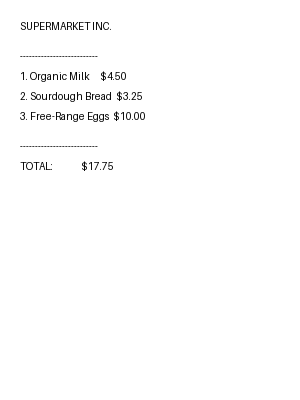

Q: What is the total price listed on this receipt?
A: The total price listed on this receipt is $17.75.

Q: How much does the Sourdough Bread cost?
A: The Sourdough Bread costs $3.25.


In [24]:
# # BONUS B: The receipt reader
from PIL import Image, ImageDraw, ImageFont

# Create a blank white image for a fake receipt
receipt = Image.new("RGB", (300, 400), color="white")
draw = ImageDraw.Draw(receipt)

# Draw receipt text
draw.text((20, 20), "SUPERMARKET INC.", fill="black")
draw.text((20, 50), "--------------------------", fill="black")
draw.text((20, 70), "1. Organic Milk     $4.50", fill="black")
draw.text((20, 90), "2. Sourdough Bread  $3.25", fill="black")
draw.text((20, 110), "3. Free-Range Eggs  $10.00", fill="black")
draw.text((20, 140), "--------------------------", fill="black")
draw.text((20, 160), "TOTAL:              $17.75", fill="black")

# Display the generated receipt in notebook
display(receipt)

# Ask model to extract target fields
receipt_q1 = "What is the total price listed on this receipt?"
receipt_q2 = "How much does the Sourdough Bread cost?"

print("Q:", receipt_q1)
print("A:", ask(receipt, receipt_q1))
print("\nQ:", receipt_q2)
print("A:", ask(receipt, receipt_q2))

 Patch Grid at 96px 


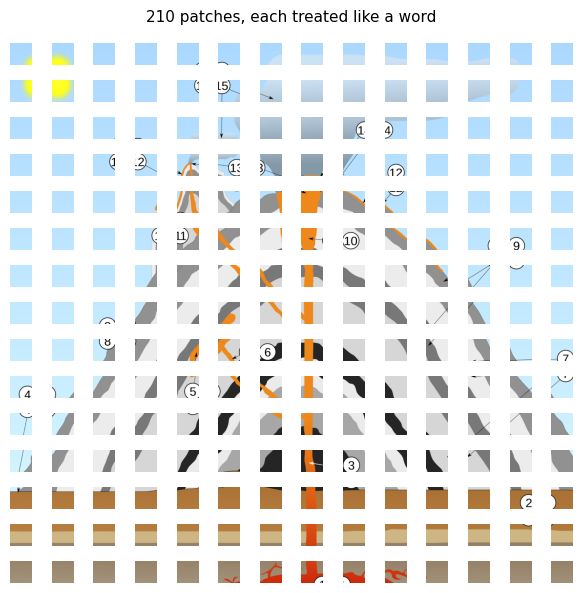

Q: Is there any tiny text or small distinct pattern visible in the corner of this image?
A: No, there is no small text or pattern visible in the corner of this image.


In [27]:
# # BONUS C: The patch size probe
import matplotlib.pyplot as plt

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

print(" Patch Grid at 96px ")
show_patches(img, patch_size=96)

# Ask about a small detail
detail_question = "Is there any tiny text or small distinct pattern visible in the corner of this image?"
print("Q:", detail_question)
print("A:", ask(img, detail_question))

## Section 12: Submission Checklist

1. Choose Runtime, then Run all, one final time. Confirm there are no errors and every question and answer pair is visible.
2. Check that every **YOUR ANSWER** cell has your words in it (search the notebook for the word "replace" to find any you missed).
3. File, Download, Download .ipynb, **with all outputs visible**. Do not clear outputs.
4. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit the notebook to Canvas. The notebook is the only deliverable.

Today you interviewed images, made one model wear five hats, caught it lying, and wrote a professional audit, all on a model small enough to run on a laptop. In Module 09 the VLM you just tamed becomes the **eyes of an agent** that perceives, reasons, and acts. You already wrote its first perception prompt in Section 8.

*Email or message me if you have any questions.*